# Fig. 9 — harmonic check along the axion-active patterns (appendix, paper `draft/main_draft.tex`, `fig:harmonic`)

Two panels: (a) Y₂Ir₂O₇, the three Γ₂⁻ basis patterns (1: Y, 2: Ir, 3: O 48f); (b) MnBi₂Te₄, the four T₂⁻ basis
patterns (1: Mn, 2: Bi, 3: Te1, 4: Te2). Q = 0.01, 0.02, 0.03, 0.05 Å per Cartesian component of the raw SMODES vector v
(entries ±1); every SCF at conv_thr 1e-10.

ΔE(Q) = E(Q) − E(0) per cell (filled) and −½ Q v·[F(Q) − F(0)] from the forces of the same SCF (open), which agree for a
harmonic energy; curve ½kQ² + a₄Q⁴ fitted to the energies. Both irreps are odd under a symmetry of the undistorted
crystal, so ΔE(−Q) = ΔE(Q): the Q < 0 points are reflections, not separate runs. The agreement tests the force
constants used for the normal modes. MnBi₂Te₄ SCFs: `phonons/amplitude_series/` (0.01, 0.02, 0.05 Å) and
`phonons/force_constants/` (0.03 Å). (Panels (a) and (d) of the Fig. 5 of 2026-11-03.)

In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
QS = (0.01, 0.02, 0.03, 0.05)                # Å
MATERIALS = {
    "Y2Ir2O7": dict(
        base=DATA / "Y2Ir2O7/dft/base/scf/out",                          # E(0), F(0); SCF 213998
        scf={m: {q: DATA / f"Y2Ir2O7/dft/GM2-_p{m}_Q{q:.2f}/scf/out" for q in QS} for m in (1, 2, 3)},
        nat=22, labels={1: "Y", 2: "Ir", 3: r"O$_{48f}$"},
        colors={1: "#2b6cb0", 2: "#7b3294", 3: "#d9821e"},
        title=r"Y$_2$Ir$_2$O$_7$ ($\Gamma_2^-$)"),
    "MnBi2Te4": dict(
        base=DATA / "MnBi2Te4/dft/base/scf/out",                         # E(0), F(0); SCF 214290
        scf={m: {q: DATA / "MnBi2Te4" / ("phonons/force_constants" if q == 0.03 else "phonons/amplitude_series")
                 / f"T2-_p{m}_Q{q:.2f}/out" for q in QS} for m in (1, 2, 3, 4)},   # 213555-8, 214108-19
        nat=14, labels={1: "Mn", 2: "Bi", 3: "Te1", 4: "Te2"},
        colors={1: "#7b3294", 2: "#2b6cb0", 3: "#d9821e", 4: "#d4ac0d"},
        title=r"MnBi$_2$Te$_4$ ($T_2^-$)"),
}
FIGSIZE = (7.0, 2.4)                         # inches; two columns (figure*)
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig9.pdf"   # or None
# ---------------

In [2]:
# ---- data: energies and forces along each pattern
import re
import numpy as np
import matplotlib.pyplot as plt

RY_EV, RYBOHR_EVA = 13.605693, 13.605693 / 0.529177


def positions(folder, prefix, nat):
    t = (folder / f"{prefix}.scf.in").read_text()
    rows = [line.split() for line in t.split("ATOMIC_POSITIONS angstrom")[1].strip().splitlines()[:nat]]
    return np.array([[float(x) for x in r[1:4]] for r in rows])


def energy_forces(folder, prefix, nat):
    t = (folder / f"{prefix}.scf.out").read_text()
    E = float(re.findall(r"!\s+total energy\s+=\s+(\S+)", t)[-1]) * RY_EV
    F = np.array(re.findall(r"atom\s+\d+ type\s+\d+\s+force =\s+(\S+)\s+(\S+)\s+(\S+)", t), float)[:nat] * RYBOHR_EVA
    return E, F


energy = {}                                  # material: pattern: (Q, ΔE, −½ Q v·ΔF)
for name, s in MATERIALS.items():
    R0 = positions(s["base"], name, s["nat"])
    E0, F0 = energy_forces(s["base"], name, s["nat"])
    energy[name] = {}
    for m, runs in s["scf"].items():
        rows = []
        for q, folder in sorted(runs.items()):
            v = (positions(folder, name, s["nat"]) - R0) / q
            E, F = energy_forces(folder, name, s["nat"])
            rows.append((q, E - E0, -0.5 * q * float((v * (F - F0)).sum())))
        energy[name][m] = np.array(rows).T
        print(f"{name} pattern {m}: ΔE / (−½Q v·ΔF) − 1 = {np.round(100 * (energy[name][m][1] / energy[name][m][2] - 1), 2)} %")

Y2Ir2O7 pattern 1: ΔE / (−½Q v·ΔF) − 1 = [-0.3  -0.15 -0.29 -0.74] %
Y2Ir2O7 pattern 2: ΔE / (−½Q v·ΔF) − 1 = [-0.03  0.21  0.32  0.76] %
Y2Ir2O7 pattern 3: ΔE / (−½Q v·ΔF) − 1 = [0.44 0.2  0.12 0.07] %
MnBi2Te4 pattern 1: ΔE / (−½Q v·ΔF) − 1 = [-0.71 -0.19  0.14  0.2 ] %
MnBi2Te4 pattern 2: ΔE / (−½Q v·ΔF) − 1 = [ 0.09 -0.07 -0.01  0.15] %
MnBi2Te4 pattern 3: ΔE / (−½Q v·ΔF) − 1 = [-0.82 -0.28  0.01  0.41] %
MnBi2Te4 pattern 4: ΔE / (−½Q v·ΔF) − 1 = [0.65 0.14 0.11 0.  ] %


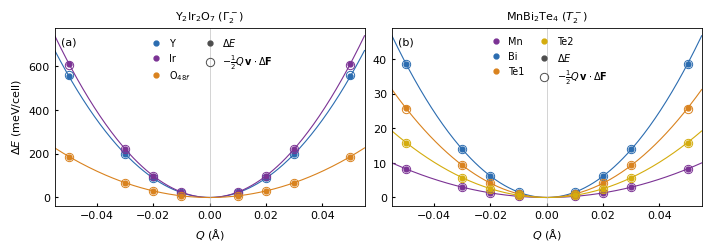

In [3]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
q = np.linspace(-0.055, 0.055, 221)
for ax, (name, s), tag in zip(axes, MATERIALS.items(), "ab"):
    for m, (Q, dE, dEf) in energy[name].items():
        c = s["colors"][m]
        k, a4 = np.linalg.lstsq(np.c_[0.5 * Q ** 2, Q ** 4], dE, rcond=None)[0]
        ax.plot(q, 1e3 * (0.5 * k * q ** 2 + a4 * q ** 4), color=c, lw=0.8)
        ax.plot(np.r_[-Q, Q], 1e3 * np.r_[dE, dE], "o", ms=3.5, color=c, label=s["labels"][m])
        ax.plot(np.r_[-Q, Q], 1e3 * np.r_[dEf, dEf], "o", ms=6, mfc="none", mew=0.7, color=c)
    ax.plot([], [], "o", ms=3.5, color="0.3", label=r"$\Delta E$")
    ax.plot([], [], "o", ms=6, mfc="none", mew=0.7, color="0.3", label=r"$-\frac{1}{2}Q\,\mathbf{v}\cdot\Delta\mathbf{F}$")
    ax.legend(fontsize=FONT_SIZE - 1, ncol=2, frameon=False, loc="upper center", handletextpad=0.3, columnspacing=1.0)
    ax.set_title(s["title"], fontsize=FONT_SIZE)
    ax.set_xlabel(r"$Q$ (Å)")
    ax.set_xlim(q[0], q[-1])
    ax.axvline(0, color="0.7", lw=0.4)
    ax.tick_params(direction="in", length=2, which="both")
    ax.text(0.02, 0.95, f"({tag})", transform=ax.transAxes, va="top", fontsize=FONT_SIZE)
axes[0].set_ylabel(r"$\Delta E$ (meV/cell)")
if SAVE_FIG:
    SAVE_FIG.parent.mkdir(exist_ok=True)
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()